In [2]:
import xarray as xr
import poligrain as plg
import matplotlib.pyplot as plt

In [3]:
(
    ds_rad,
    ds_cmls,
    ds_gauges_municp,
    ds_gauge_smhi,
) = plg.example_data.load_openmrg(data_dir="example_data", subset="8d")

File already exists at example_data/openmrg_cml_8d.nc
Not downloading!
File already exists at example_data/openmrg_rad_8d.nc
Not downloading!
File already exists at example_data/openmrg_municp_gauge_8d.nc
Not downloading!
File already exists at example_data/openmrg_smhi_gauge_8d.nc
Not downloading!


Text(0.5, 1.0, '')

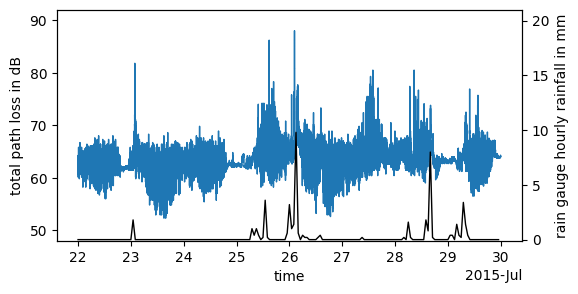

In [4]:
cml_id = 10058
ds_cml = ds_cmls.sel(cml_id=cml_id).isel(sublink_id=0)

fig, ax = plt.subplots(figsize=(6, 3))
(ds_cml.tsl - ds_cml.rsl).plot(ax=ax, linewidth=1)
ax.set_ylim(48, 92)
ax.set_ylabel("total path loss in dB")

ax2 = ax.twinx()
ds_gauges_municp.rainfall_amount.sel(id='Lbom').resample(time='1h').sum().plot(ax=ax2, color='k', zorder=-1, linewidth=1)
ax2.set_ylim(-0.1, 21)
ax2.set_ylabel("rain gauge hourly rainfall in mm")
ax.set_title('')
ax2.set_title('')

Text(0.5, 1.0, '')

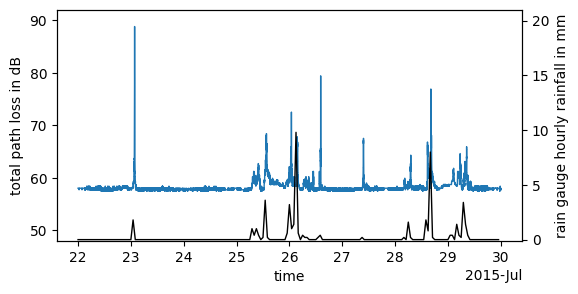

In [17]:

cml_id = 10059
ds_cml = ds_cmls.sel(cml_id=cml_id).isel(sublink_id=0)

fig, ax = plt.subplots(figsize=(6, 3))
(ds_cml.tsl - ds_cml.rsl).plot(ax=ax, linewidth=1)
ax.set_ylim(48, 92)
ax.set_ylabel("total path loss in dB")

ax2 = ax.twinx()
ds_gauges_municp.rainfall_amount.sel(id='Lbom').resample(time='1h').sum().plot(ax=ax2, color='k', zorder=-1, linewidth=1)
ax2.set_ylim(-0.1, 21)
ax2.set_ylabel("rain gauge hourly rainfall in mm")
ax.set_title('')
ax2.set_title('')

Text(0.5, 0, 'time')

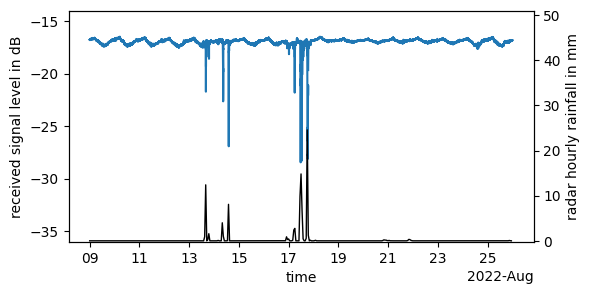

In [23]:
ds_smls = xr.open_dataset('/Users/chwala-c/data/OpenSat4Weather_data/sml_data_2022.nc')
ds_radar_along_smls = xr.open_dataset('/Users/chwala-c/data/OpenSat4Weather_data/radar_along_sml_data_2022.nc')
i_sml = 0

fig, ax = plt.subplots(figsize=(6, 3))
ds_smls.rsl.isel(sml_id=i_sml).sel(time=slice('2022-08-09', '2022-08-25')).plot()
ax.set_ylim(-36, -14)
ax.set_ylabel("received signal level in dB")

ax2 = ax.twinx()
ds_radar_along_smls.rainfall_amount.isel(sml_id=i_sml).resample(time='1h').sum().sel(time=slice('2022-08-09', '2022-08-25')).plot(
    ax=ax2, color='k', zorder=-1, linewidth=1,
)
ax2.set_ylim(-0.2, 51)
ax2.set_ylabel("radar hourly rainfall in mm")
ax.set_title('')
ax2.set_title('')
ax.set_xlabel("time")


Text(0.5, 0, 'time')

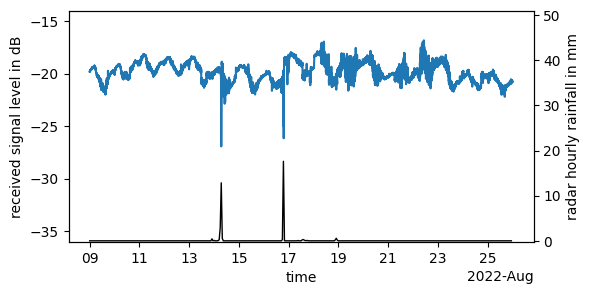

In [135]:
ds_smls = xr.open_dataset('/Users/chwala-c/data/OpenSat4Weather_data/sml_data_2022.nc')
ds_radar_along_smls = xr.open_dataset('/Users/chwala-c/data/OpenSat4Weather_data/radar_along_sml_data_2022.nc')
sml_id = 'FRA-00157'

fig, ax = plt.subplots(figsize=(6, 3))
ds_smls.rsl.sel(sml_id=sml_id).sel(time=slice('2022-08-09', '2022-08-25')).plot()
ax.set_ylim(-36, -14)
ax.set_ylabel("received signal level in dB")

ax2 = ax.twinx()
ds_radar_along_smls.rainfall_amount.sel(sml_id=sml_id).resample(time='1h').sum().sel(time=slice('2022-08-09', '2022-08-25')).plot(
    ax=ax2, color='k', zorder=-1, linewidth=1,
)
ax2.set_ylim(-0.2, 51)
ax2.set_ylabel("radar hourly rainfall in mm")
ax.set_title('')
ax2.set_title('')
ax.set_xlabel("time")


In [25]:
!curl -OL https://github.com/OpenSenseAction/OS_data_format_conventions/raw/main/notebooks/data/OpenSense_PWS_example_format_data.nc

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 5687k  100 5687k    0     0  2669k      0  0:00:02  0:00:02 --:--:-- 6731k


In [58]:
ds_pwss, ds_reference = plg.example_data.load_ams_pws()

File already exists at ams_pws_full_period.nc
Not downloading!
File already exists at ams_gauges_full_period.nc
Not downloading!


(0.0, 2000.0)

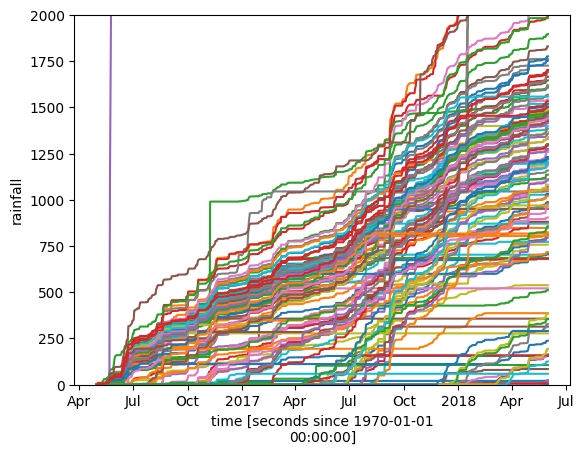

In [59]:
ds_pwss.rainfall.resample(time='1d').sum().cumsum(dim='time').plot.line(x='time', add_legend=False);
plt.ylim(0, 2000)

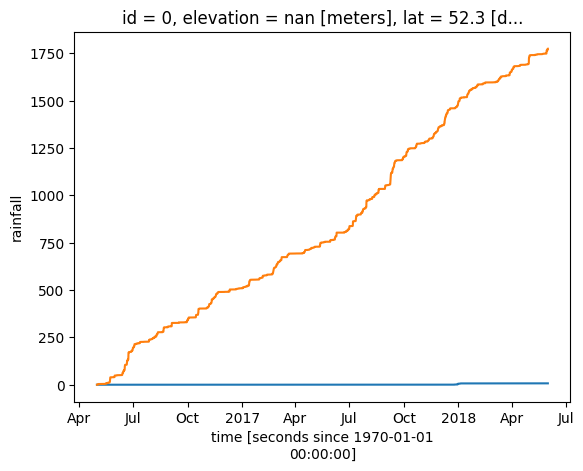

In [ ]:
ds_pwss.sel(id='ams74').rainfall.cumsum().plot()
ds_reference.isel(id=0).rainfall.cumsum().plot()

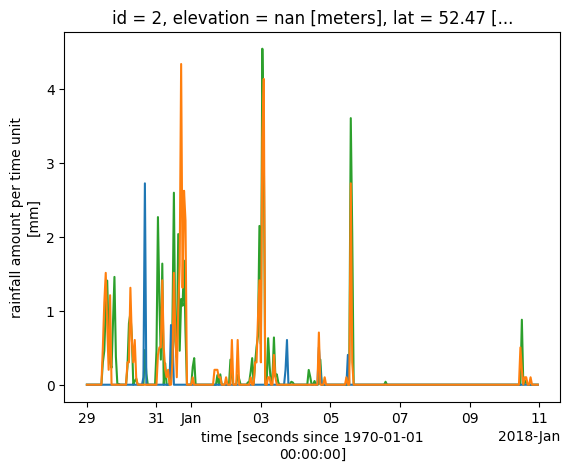

In [91]:
t_start = '2017-12-29'
t_end = '2018-01-10'
ds_pwss.sel(id='ams74').sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum().plot(zorder=10)
ds_pwss.sel(id='ams75').sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum().plot(zorder=10)
ds_reference.isel(id=2).sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum().plot()

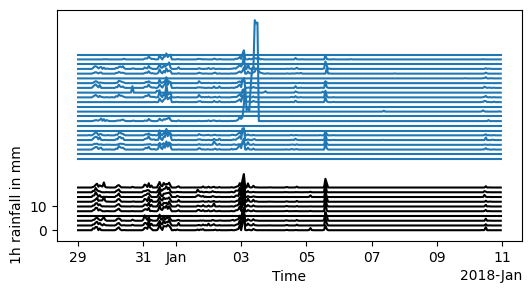

In [125]:
t_start = '2017-12-29'
t_end = '2018-01-10'

fig, ax = plt.subplots(figsize=(6, 3))
for i in range(60, 83):
    (
        ds_pwss.sel(id=f'ams{i}').sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum() + 2*i - 90
     ).plot(ax=ax, zorder=10, color='C0')

for i in range(0, 10):
    (
        ds_reference.isel(id=i).sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum() + 2*i
    ).plot(ax=ax, color='k')
ax.set_title('')
ax.set_xlabel('Time')
ax.set_ylabel('1h rainfall in mm                                    ')
ax.set_yticks([0, 10])

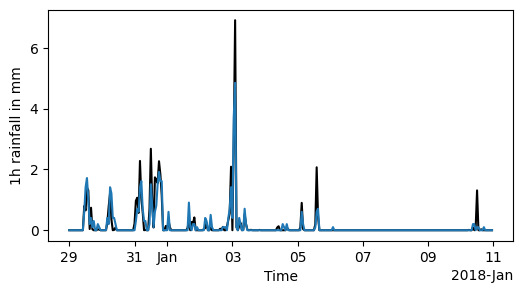

In [140]:
pws_id = 'ams134'
fig, ax = plt.subplots(figsize=(6, 3))
ds_pwss.sel(id=pws_id).sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum().plot(ax=ax, color='C0', zorder=10)
ds_reference.isel(id=0).sel(time=slice(t_start, t_end)).rainfall.resample(time='1h').sum().plot(ax=ax, color='k')
ax.set_title('')
ax.set_xlabel('Time')
ax.set_ylabel('1h rainfall in mm')
ax.set_yticks([0, 2, 4, 6])


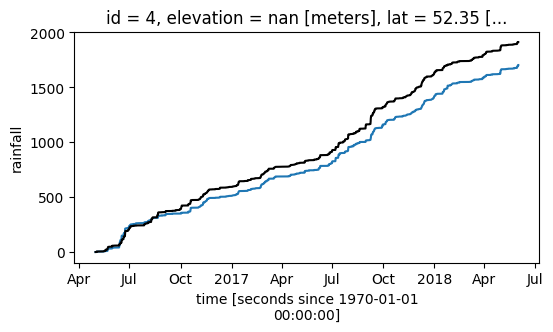

In [133]:
pws_id = 'ams134'
fig, ax = plt.subplots(figsize=(6, 3))
ds_pwss.sel(id=pws_id).rainfall.resample(time='1h').sum().cumsum().plot(ax=ax, color='C0')
ds_reference.isel(id=4).rainfall.resample(time='1h').sum().cumsum().plot(ax=ax, color='k')
